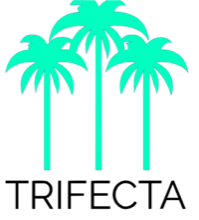

# Cooking in Dutch print, 1500–1940: a frame-oriented look

Every food mention in the corpus was annotated with a **frame**: what the text does with the food.

| frame | the food is … | frame elements kept here |
|---|---|---|
| **COOKING_CREATION** | prepared | *Food_Product* (what is made), *Method* (how) |
| **INGESTION** | eaten or drunk | |
| **CURE** | used as medicine | *Affliction*, *Food_Treatment* |
| **PRESERVING** | kept | |

Questions: which frames dominate in which kinds of book and when; what is cooked and how; which foods move between
the kitchen, the table and the apothecary; how the words for cooking change.

**Read before trusting a number**
- **The annotations are made by a language model** (with checks), not by hand. Frame elements are only kept when their
  words actually occur in the passage ("grounded"). Where the model gives a *Food_Product* or *Method*, about 9 and 8
  in 10 are grounded; but only about **4 in 10 cooking mentions** end up with a usable product or method, so B–D
  describe that subset.
- **The corpus is a sample**, and uneven over time; **dates are edition years**; **genres** come from our own rules
  or, where those fail, from library catalogues (column `genre_source`).
- A mention counts once, whatever the quantity.


In [ ]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# ✏️ Where the data is, RELATIVE TO THIS NOTEBOOK: "." = the same folder (as in the export).
DATA_SUBDIR = "."
DATA_DIR = Path(DATA_SUBDIR).resolve()   # Jupyter and VS Code run a notebook in its own folder
if not (DATA_DIR / "mentions.parquet").exists():
    raise FileNotFoundError(f"mentions.parquet is not in {DATA_DIR}. Put this notebook next to the export "
                            "(food_harvest folder), or set DATA_SUBDIR.")
m = pd.read_parquet(DATA_DIR / "mentions.parquet")
f = m[m["status"].eq("frame")].copy()
f["elements"] = f["frame_elements"].map(lambda s: json.loads(s) if isinstance(s, str) and s else {})
FRAMES = ["COOKING_CREATION", "INGESTION", "CURE", "PRESERVING"]
COLORS = {"COOKING_CREATION": "#e45756", "INGESTION": "#4c78a8", "CURE": "#54a24b", "PRESERVING": "#b279a2"}
print(f"📂 {DATA_DIR}\n{len(f):,} framed mentions in {f.work_id.nunique():,} works; with a year: {f.year.notna().mean():.0%}")
f["frame"].value_counts().to_frame("mentions")

## A. Which frame, in which kind of book, and when
Share of each frame per genre (books with at least 100 framed mentions), and per 25 years.

In [ ]:
g = pd.crosstab(f["genre"], f["frame"])[FRAMES]
g = g[g.sum(axis=1) >= 100]
share = g.div(g.sum(axis=1), axis=0).sort_values("COOKING_CREATION")
ax = share.plot.barh(stacked=True, figsize=(9, 4.5), color=[COLORS[c] for c in FRAMES], width=0.8)
ax.set_xlabel("share of the genre's framed mentions"); ax.set_ylabel(""); ax.legend(loc="lower right", fontsize=8)
for i, n in enumerate(g.loc[share.index].sum(axis=1)):
    ax.text(1.01, i, f"{n:,}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
t = f.dropna(subset=["year"]).assign(period=lambda d: (d.year // 25 * 25).astype(int))
t = pd.crosstab(t["period"], t["frame"])[FRAMES].loc[1550:1875]   # after 1900 too few mentions for a share
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
t.div(t.sum(axis=1), axis=0).plot.area(ax=a1, color=[COLORS[c] for c in FRAMES], linewidth=0)
a1.set_ylabel("share"); a1.legend(loc="upper left", fontsize=8); a1.set_xlabel("")
a2.bar(t.index, t.sum(axis=1), width=20, color="#bbbbbb")
a2.set_ylabel("mentions"); plt.tight_layout(); plt.show()

**Reading it.** Cookbooks (`RECIPE_PRACTICE`) are what you would expect: mostly cooking, with a solid share of
**cure** (recipes for the sick, home remedies) and most of the **preserving**. Medical books are nearly all cure and
cooking (preparing a remedy *is* cooking). Literary and periodical texts are about **eating and drinking**. Over time
the share of cure falls, the share of ingestion rises: read with the counts below the chart, since the early periods
are small.

## B. What is cooked
The *Food_Product* of the cooking frame: what the passage says is being made (grounded only).

In [ ]:
cook = f[f.frame == "COOKING_CREATION"].copy()
def grounded(row, key):
    v = row.elements.get(key)
    return v.lower() if isinstance(v, str) and v and v.lower() in str(row.context).lower() else None
cook["product"] = [grounded(r, "COOKING_CREATION_Food_Product") for r in cook.itertuples()]
cook["method_raw"] = [grounded(r, "COOKING_CREATION_Method") for r in cook.itertuples()]
print(f"cooking mentions: {len(cook):,}; with a grounded product: {cook['product'].notna().mean():.0%}, method: {cook['method_raw'].notna().mean():.0%}")
cook["product"].value_counts().head(30).to_frame("mentions").T

In [ ]:
PERIODS = [(1500, 1649), (1650, 1749), (1750, 1849), (1850, 1940)]   # note sambal after 1850: the Indies kitchen in print
cols = {}
for a, b in PERIODS:
    p = cook[cook.year.between(a, b)]["product"].value_counts()
    cols[f"{a}–{b}"] = (p.head(12).index + " (" + p.head(12).astype(str).values + ")").tolist()
pd.DataFrame({k: pd.Series(v) for k, v in cols.items()})

## C. How: the methods, and their words
The *Method* element, normalised to a verb (hand-made list below: *gekookt, kookt, kooken* → koken). The list is
short on purpose; anything not on it stays `other`. Note **sieden / zieden** (*gesoden*): the older word for boiling.

In [ ]:
METHODS = [  # (verb, pattern on the Method words); first match wins
    ("sieden", r"\b(?:ge)?[sz](?:ie|ee)d|\bgesoden|\bzood"),
    ("koken", r"\b(?:ge|door)?k(?:oo|o)k"),
    ("braden", r"\b(?:ge)?braa?d|\bbraet"),
    ("bakken", r"\b(?:ge)?bac?kk?(?:en|t)?\b|\bgebacken"),
    ("stoven", r"\b(?:ge)?stoo?v"),
    ("roosteren", r"rooster"),
    ("smelten", r"smelt"),
    ("mengen", r"\b(?:ge)?meng"),
    ("stampen", r"stamp"),
    ("snijden", r"\b(?:ge)?sn(?:ij|y|e)d|\bsned"),
    ("weken", r"\b(?:ge)?wee?k(?:en|t)\b"),
    ("trekken", r"\btrek|\bgetrokken"),
    ("distilleren", r"distill|distil"),
    ("branden", r"\b(?:ge)?brand"),
    ("brouwen", r"brouw"),
]
def verb(s):
    if not isinstance(s, str):
        return None
    for v, p in METHODS:
        if re.search(p, s):
            return v
    return "other"
cook["method"] = cook["method_raw"].map(verb)
cook["method"].value_counts().to_frame("mentions").T

In [ ]:
# what the verb list does not cover yet: extend METHODS above with what you see here
cook.loc[cook.method == "other", "method_raw"].value_counts().head(30).to_frame("mentions").T

In [ ]:
mt = cook.dropna(subset=["method", "year"]).query("method != 'other'").assign(period=lambda d: (d.year // 50 * 50).astype(int))
mt = pd.crosstab(mt["method"], mt["period"]).loc[:, 1550:1900]
show = mt.sum(axis=1).sort_values(ascending=False).index[:10]
ax = mt.loc[show].div(mt.sum(axis=0), axis=1).T.plot(marker="o", figsize=(9, 4))
ax.set_ylabel("share of the period's methods"); ax.set_xlabel(""); ax.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()
mt.loc[show]

**Reading it.** **Sieden** is the main boiling word of the earliest books (most of the few methods before 1600, 41 in
1650–1699) and fades as **koken** takes over (274 in 1700–1749): the same act, a new word. *Braden* and *bakken* are
there throughout; *distilleren* and *trekken* (infusing) cluster in 1650–1749, the age of household remedies in
recipe form. Mind the counts: the periods before 1650 are small.

## D. Which foods, which methods
For the foods most often cooked (the annotated food word, `pref_label`): how they are prepared.

In [ ]:
fm = cook.dropna(subset=["method"]).query("method != 'other'")
top_food = fm["pref_label"].value_counts().head(15).index
x = pd.crosstab(fm.loc[fm.pref_label.isin(top_food), "pref_label"], fm.loc[fm.pref_label.isin(top_food), "method"])
x = x[x.sum().sort_values(ascending=False).index[:10]]
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(x.div(x.sum(axis=1), axis=0).values, cmap="Blues", aspect="auto")
ax.set_xticks(range(x.shape[1]), x.columns, rotation=45, ha="right"); ax.set_yticks(range(x.shape[0]), x.index)
for (i, j), v in pd.DataFrame(x.values).stack().items():
    if v: ax.text(j, i, v, ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="share of the food's methods"); plt.tight_layout(); plt.show()

## E. Between kitchen, table and apothecary
For one food at a time: the share of each frame per period. Change `FOOD` (the `pref_label`, e.g. *suiker*, *thee*,
*koffie*, *kaneel*, *peper*, *wijn*, *azijn*, *honing*).

In [ ]:
FOOD = "suiker"
one = f[(f.pref_label == FOOD) & f.year.notna()].assign(period=lambda d: (d.year // 50 * 50).astype(int))
ft = pd.crosstab(one["period"], one["frame"]).reindex(columns=FRAMES, fill_value=0)
ax = ft.div(ft.sum(axis=1), axis=0).plot.bar(stacked=True, color=[COLORS[c] for c in FRAMES], figsize=(9, 3.5), width=0.85)
ax.set_title(f"{FOOD}: frames per 50 years (mentions above the bars)"); ax.set_xlabel(""); ax.legend(fontsize=8, loc="upper left")
for i, n in enumerate(ft.sum(axis=1)):
    ax.text(i, 1.01, n, ha="center", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# all foods at once: which ones shift most from cure to cooking or eating (foods with 40+ dated mentions)
dated = f.dropna(subset=["year"])
early, late = dated[dated.year < 1700], dated[dated.year >= 1750]
rows = []
for food, n in dated["pref_label"].value_counts().items():
    if n < 40:
        break
    e, l = early[early.pref_label == food], late[late.pref_label == food]
    if len(e) >= 10 and len(l) >= 10:
        rows.append({"food": food, "mentions": n, "cure before 1700": (e.frame == "CURE").mean(), "cure after 1750": (l.frame == "CURE").mean()})
shift = pd.DataFrame(rows).assign(change=lambda d: d["cure after 1750"] - d["cure before 1700"]).sort_values("change")
shift.round(2).head(12)

**Reading it.** **Tea** is the clearest case: a third of its mentions before 1700 are medicinal, after 1750 only 6%.
Brandy, cloves, milk, citrus and olive oil follow the same way, from the apothecary to the kitchen and the table.
The table lists the foods whose share of *cure* mentions drops most between the seventeenth and the later eighteenth
century. Read the passages before believing a shift: a change of genre in the sample (more cookbooks, fewer herbals)
moves every food the same way, so compare with section A.

## F. Read the passages
The passages behind any number: choose a food, a frame or a method.

In [ ]:
FOOD, FRAME, METHOD = "suiker", "COOKING_CREATION", None   # METHOD e.g. "sieden"
r = cook if METHOD else f
r = r[(r.pref_label == FOOD) & (r.frame == FRAME)]
if METHOD:
    r = r[r.method == METHOD]
for x in r.sort_values("year").head(12).itertuples():
    print(f"{x.year}  {x.genre:16} {x.title[:40]:40}  …{str(x.context)[:170]}…")

## Where to go from here
- **Ingredients together**: which foods are cooked *with* which (the passages name several): co-occurrence as in the
  term-relations notebook.
- **Recipes as units**: a passage is ~600 characters; a recipe is the natural unit, and the cookbooks' structure
  (titles, recipe headings) would give it.
- **Trade and table**: the kg_mockup notebooks show when coffee, tea and sugar arrive in the Republic; here you can see
  when they move from the apothecary to the kitchen.


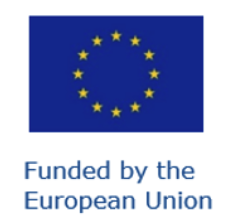